# Supply Chain Complete Analysis

This project presents an end-to-end analysis of supply chain and delivery performance using the DataCo Supply Chain dataset.

The analysis focuses on data cleaning, feature engineering, profitability analysis, delivery delays, bottleneck detection, root cause analysis, time-based patterns, and machine learning modeling to identify orders at risk of late delivery.

## 1. Importing Required Libraries

The required Python libraries are imported for data manipulation, exploratory data analysis, visualization, statistical analysis, and machine learning.

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

from IPython.display import display

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report
)
from sklearn.ensemble import RandomForestClassifier

from collections import Counter
from imblearn.over_sampling import SMOTE

# Plotting style
sns.set_theme(style="whitegrid")

# Project color palette
primary_color = "#17233F"
accent_color = "#36A7A4"
secondary_color = "#2D9185"
danger_color = "#800000"

viridis_colors = sns.color_palette("viridis", 10)

plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.family"] = "DejaVu Sans"

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Data Loading

The DataCo Supply Chain dataset is loaded into a Pandas DataFrame. The dataset contains information related to orders, products, customers, shipping, delivery performance, and profitability.

In [ ]:
df = pd.read_csv(
    "DataCoSupplyChainDataset.csv",
    encoding="latin-1"
)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (180519, 53)


## 3. Exploratory Data Analysis

An initial exploratory analysis is performed to understand the size and structure of the dataset. The analysis includes checking the available columns, duplicate records, and missing values.

In [ ]:
print("Rows, Columns:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nNumber of duplicates:", df.duplicated().sum())

print("\nMissing values (Top 20):")
print(
    df.isna()
      .sum()
      .sort_values(ascending=False)
      .head(20)
)

Rows, Columns: (180519, 53)

Columns:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Pro

## 4. Data Cleaning

The dataset contains several columns that are either completely missing, redundant, contain sensitive customer information, have no analytical value, or provide duplicate information.

These columns are removed to create a cleaner and more focused analytical dataset.

In [ ]:
columns_to_drop = [
    'Product Description',
    'Product Image',
    'Customer Email',
    'Customer Password',
    'Customer Fname',
    'Customer Lname',
    'Customer Street',
    'Customer Zipcode',
    'Order Zipcode',
    'Longitude',
    'Latitude',
    'Order Item Cardprod Id',
    'Order Item Id',
    'Order Item Discount',
    'Order Item Discount Rate',
    'Order Item Product Price',
    'Order Item Quantity',
    'Order Item Total',
    'Category Id',
    'Department Id',
    'Order Id',
    'Order Customer Id',
    'Customer Id',
    'Product Card Id',
    'Product Category Id',
    'Benefit per order',
    'Product Status',
    'Customer City',
    'Order City',
    'Order Country',
    'Order State',
    'Customer State',
    'Market'
]

df = df.drop(
    columns=columns_to_drop
)

print("After column cleaning:", df.shape)

After column cleaning: (180519, 20)


### Removing Cancelled Orders

Cancelled shipments are removed from the dataset because they do not represent completed delivery outcomes. This ensures that the subsequent delivery and delay analysis is based on meaningful shipment records.

In [ ]:
df = df[
    df['Delivery Status'] != 'Shipping canceled'
].copy()

print("After removing cancelled orders:", df.shape)

After removing cancelled orders: (172765, 20)


### Date Conversion

The order and shipping date columns are converted into datetime format. This allows the analysis to calculate order processing time and identify delivery patterns across months, days of the week, and hours of the day.

In [ ]:
for c in [
    'order date (DateOrders)',
    'shipping date (DateOrders)'
]:
    df[c] = pd.to_datetime(
        df[c],
        errors='coerce',
        dayfirst=False
    )

print("Date columns converted successfully.")

Date columns converted successfully.


### Data Quality Check After Cleaning

The cleaned dataset is checked again to confirm the final number of observations and verify that the important analytical columns do not contain missing values.

In [ ]:
print("Rows, Columns:", df.shape)

print("\nMissing values (Top 5):")
print(
    df.isna()
      .sum()
      .sort_values(ascending=False)
      .head(5)
)

Rows, Columns: (172765, 20)

Missing values (Top 5):
Type                             0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Sales per customer               0
Delivery Status                  0
dtype: int64


## 5. Feature Engineering

New features are created to measure order processing time and delivery delays. Additional time-based features are extracted from the order date to support the later time-based analysis.

In [ ]:
# Calculate order processing time
df['Order Processing Time'] = (
    df['shipping date (DateOrders)'] -
    df['order date (DateOrders)']
).dt.days

# Calculate delivery delay
df['Delay'] = (
    df['Order Processing Time'] -
    df['Days for shipment (scheduled)']
)

# Identify delayed orders
df['Is_Delayed'] = df['Delay'] > 0

# Extract time-based features
df['order_month'] = df['order date (DateOrders)'].dt.month
df['order_day'] = df['order date (DateOrders)'].dt.day_name()
df['order_hour'] = df['order date (DateOrders)'].dt.hour

df.describe()

,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Late_delivery_risk,order date (DateOrders),Order Item Profit Ratio,Sales,Order Profit Per Order,Product Price,shipping date (DateOrders),Order Processing Time,Delay,order_month,order_hour
count,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000
mean,3.498596,2.933100,183.165948,0.572900,2016-06-12 15:25:39.457991936,0.120801,203.828493,22.032360,141.278595,2016-06-16 03:25:14.452927488,3.472816,0.539716,6.235511,11.482604
min,0.000000,0.000000,7.490000,0.000000,2015-01-01 00:00:00,-2.750000,9.990000,-4274.979980,9.990000,2015-01-03 00:00:00,0.000000,-2.000000,1.000000,0.000000
25%,2.000000,2.000000,104.379997,0.000000,2015-09-21 18:01:00,0.080000,119.980003,7.030000,50.000000,2015-09-25 08:59:00,2.000000,0.000000,3.000000,5.000000
50%,3.000000,4.000000,163.990005,1.000000,2016-06-11 08:11:00,0.270000,199.919998,31.520000,59.990002,2016-06-15 03:38:00,3.000000,1.000000,6.000000,11.000000
75%,5.000000,4.000000,247.399994,1.000000,2017-02-28 21:08:00,0.360000,299.950012,64.800003,199.990005,2017-03-04 08:00:00,5.000000,1.000000,9.000000,17.000000
max,6.000000,4.000000,1939.989990,1.000000,2018-01-31 23:38:00,0.500000,1999.989990,911.799988,1999.989990,2018-02-06 22:14:00,6.000000,4.000000,12.000000,23.000000
std,1.623446,1.373405,120.141871,0.494659,NaN,0.466610,132.392520,104.355313,139.862956,NaN,1.670187,1.494150,3.405593,6.927276


## 5.1 Delivery Delay Distribution

The newly created delay indicator is examined to understand how many orders were delivered late versus on time. This provides an initial view of the overall delivery performance.

In [ ]:
print("Delayed vs On-Time Orders:")
print(df['Is_Delayed'].value_counts())

print("\nDelay Percentage:")
print(
    (df['Is_Delayed'].value_counts(normalize=True) * 100).round(2)
)

Delayed vs On-Time Orders:
Is_Delayed
True     94523
False    78242
Name: count, dtype: int64

Delay Percentage:
Is_Delayed
True     54.71
False    45.29
Name: proportion, dtype: float64


## 6. Profitability Analysis

Order-level profitability is analyzed using the `Order Profit Per Order` variable. Each order is classified as profitable, loss-making, or break-even to understand the overall profitability distribution of the supply chain.

In [ ]:
# Create profitability classification
df['Profitability Flag'] = np.where(
    df['Order Profit Per Order'] > 0,
    'Profit',
    np.where(
        df['Order Profit Per Order'] < 0,
        'Loss',
        'Break-even'
    )
)

print("Profitability Distribution:")
print(df['Profitability Flag'].value_counts())

Profitability Distribution:
Profitability Flag
Profit        139354
Loss           32295
Break-even      1116
Name: count, dtype: int64


### 6.1 Profitability Distribution

The distribution of profitable, loss-making, and break-even orders is visualized to understand the overall profitability profile of the supply chain.

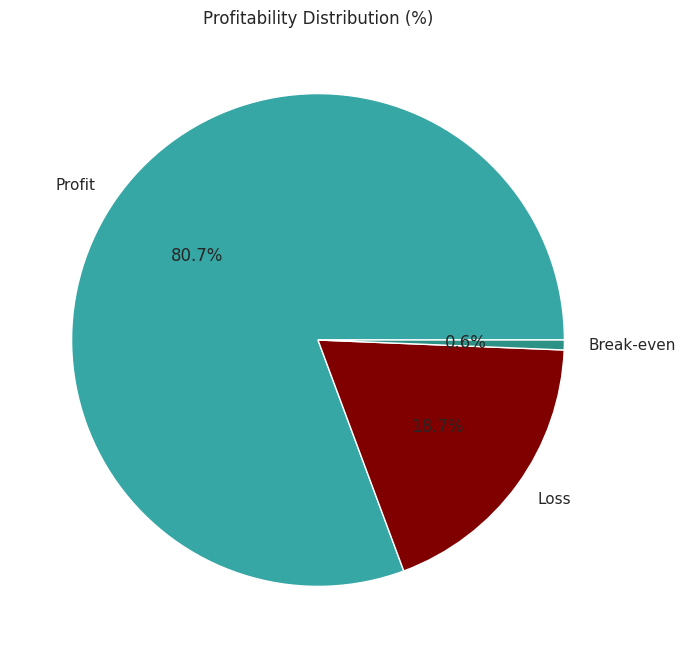

In [ ]:
profit_counts = (
    df['Profitability Flag']
    .value_counts(normalize=True) * 100
)

profit_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    colors=[
        accent_color,
        danger_color,
        secondary_color
    ],
    figsize=(8, 8)
)

plt.title('Profitability Distribution (%)')
plt.ylabel('')
plt.show()

## 7. Business Performance KPIs

Key performance indicators are calculated to establish a baseline for order volume, delivery performance, delay severity, and financial impact.

In [ ]:
def format_func(value):
    if value >= 1e6:
        return f'{value/1e6:.1f}M $'
    elif value >= 1e3:
        return f'{value/1e3:.1f}K $'
    else:
        return f'{value:.0f} $'


delayed_df = df[df['Delay'] > 0]

metrics = {}

metrics['Total Orders'] = len(df)

metrics['Late Deliveries'] = len(delayed_df)

metrics['90% Delay (days)'] = delayed_df['Delay'].quantile(0.90)

metrics['On time Delivery %'] = (
    1 - float(metrics['Late Deliveries']) / metrics['Total Orders']
) * 100

metrics['Late Delivery %'] = (
    float(metrics['Late Deliveries']) / metrics['Total Orders']
) * 100

metrics['Total Profit'] = format_func(
    df.loc[
        df['Order Profit Per Order'] > 0,
        'Order Profit Per Order'
    ].sum()
)

metrics['Total Loss due to delays'] = format_func(
    df.loc[
        df['Delay'] > 0,
        'Order Profit Per Order'
    ].sum()
)

print('\n--- Business KPIs ---\n')

for k, v in metrics.items():
    if isinstance(v, float):
        print(f"{k}: {v:.2f}")
    else:
        print(f"{k}: {v}")


--- Business KPIs ---

Total Orders: 172765
Late Deliveries: 94523
90% Delay (days): 3.00
On time Delivery %: 45.29
Late Delivery %: 54.71
Total Profit: 7.5M $
Total Loss due to delays: 2.1M $


## 8. Profitability vs Delivery Time Analysis

The relationship between delivery delay and order profitability is analyzed by calculating the mean profit, total profit, and number of orders for each delay level. This helps assess whether increasing delivery delays are associated with changes in order profitability.

In [ ]:
profit_metrics = (
    df.groupby('Delay')['Order Profit Per Order']
      .agg(
          mean_profit='mean',
          total_profit='sum',
          order_count='count'
      )
      .reset_index()
)

profit_metrics

,Delay,mean_profit,total_profit,order_count
0,-2,23.360134,4.875961e+05,20873
1,-1,21.604769,4.476292e+05,20719
2,0,22.249118,8.154302e+05,36650
3,1,22.333227,1.194895e+06,53503
4,2,21.128491,5.821110e+05,27551
5,3,20.031412,1.356527e+05,6772
6,4,21.368783,1.431067e+05,6697


### 8.1 Delay Distribution

The distribution of orders across different delay levels is calculated as a percentage of total orders. This helps identify the most common delivery delay patterns.

In [ ]:
delay_distribution = (
    df['Delay']
      .value_counts(normalize=True)
      .sort_index() * 100
).reset_index()

delay_distribution.columns = [
    'Delay_Days',
    'Percentage'
]

delay_distribution

,Delay_Days,Percentage
0,-2,12.081730
1,-1,11.992591
2,0,21.213788
3,1,30.968657
4,2,15.947096
5,3,3.919775
6,4,3.876364


### 8.2 Delay Distribution & Profit Analysis by Delay Days

The delay distribution and profitability metrics are visualized together to identify the most common delay levels and examine how total and mean order profit vary across different delay days.


Profit Metrics by Delay Day:


,Delay,mean_profit,total_profit,order_count
0,-2,23.4,487596.1,20873
1,-1,21.6,447629.2,20719
2,0,22.2,815430.2,36650
3,1,22.3,1194894.7,53503
4,2,21.1,582111.0,27551
5,3,20.0,135652.7,6772
6,4,21.4,143106.7,6697



Delay Distribution (%):


,Delay_Days,Percentage
0,-2,12.081730
1,-1,11.992591
2,0,21.213788
3,1,30.968657
4,2,15.947096
5,3,3.919775
6,4,3.876364


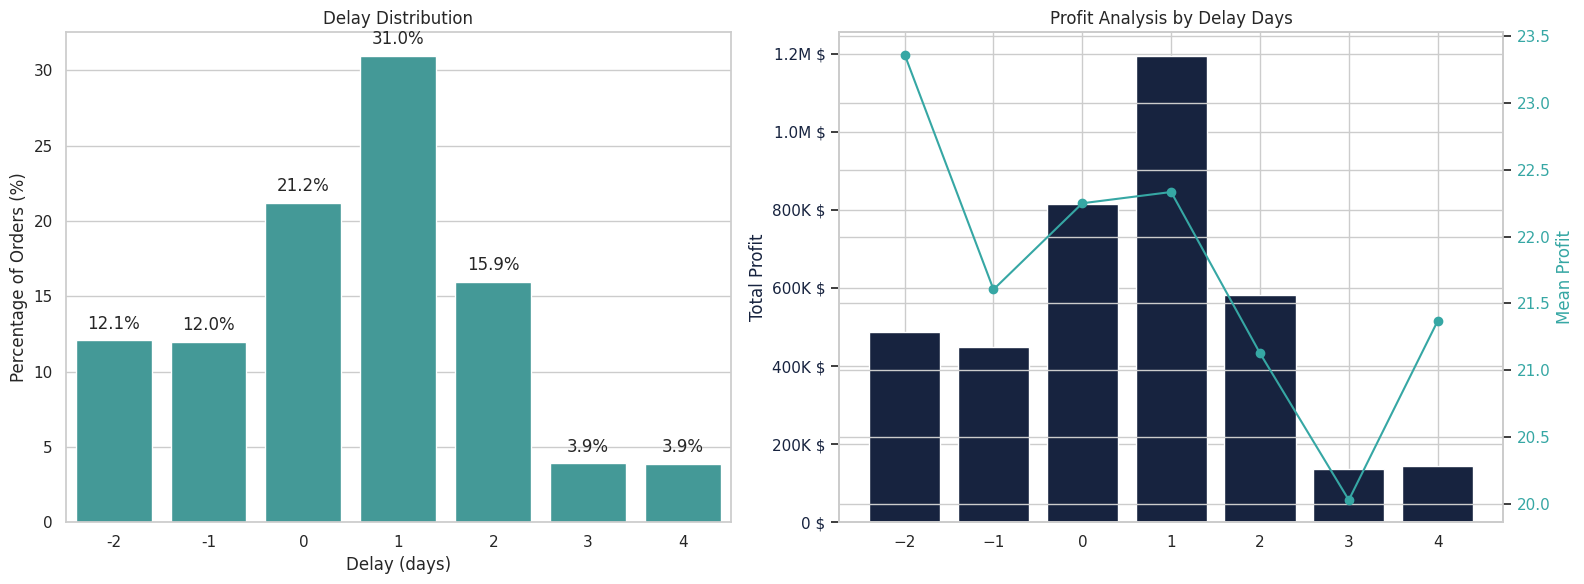

In [ ]:
print("\nProfit Metrics by Delay Day:")
display(profit_metrics.round(1))

print("\nDelay Distribution (%):")
display(delay_distribution)

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

# --------------------------------
# First subplot: Delay Distribution
# --------------------------------
sns.barplot(
    x='Delay_Days',
    y='Percentage',
    data=delay_distribution,
    color=accent_color,
    ax=ax1
)

ax1.set_title('Delay Distribution')
ax1.set_xlabel('Delay (days)')
ax1.set_ylabel('Percentage of Orders (%)')

for bar in ax1.patches:
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f'{height:.1f}%',
        ha='center',
        va='bottom'
    )

# --------------------------------
# Second subplot: Profit Analysis
# --------------------------------
ax2.set_ylabel(
    "Total Profit",
    color=primary_color
)

ax2.bar(
    profit_metrics['Delay'],
    profit_metrics['total_profit'],
    color=primary_color,
    label='Total Profit'
)

ax2.tick_params(
    axis='y',
    labelcolor=primary_color
)

ax3 = ax2.twinx()

ax3.set_xlabel("Delay Days")

ax3.set_ylabel(
    "Mean Profit",
    color=accent_color
)

ax3.plot(
    profit_metrics['Delay'],
    profit_metrics['mean_profit'],
    marker='o',
    label='Mean Profit',
    color=accent_color
)

ax3.tick_params(
    axis='y',
    labelcolor=accent_color
)

# Format Total Profit axis
def format_func(value, tick_number):
    if value >= 1e6:
        return f'{value/1e6:.1f}M $'
    elif value >= 1e3:
        return f'{value/1e3:.0f}K $'
    else:
        return f'{value:.0f} $'

ax2.yaxis.set_major_formatter(
    ticker.FuncFormatter(format_func)
)

ax2.set_title('Profit Analysis by Delay Days')

plt.tight_layout()
plt.show()

## 9. Bottleneck Detection

Delay percentage is analyzed across six key operational dimensions to identify areas where the fulfillment process experiences higher delivery delays.

The analysis covers Order Region, Customer Segment, Shipping Mode, Order Status, Type, and Department Name.

In [ ]:
def compute_delay_pct_by_category(category):
    cat_df = (
        df.groupby(category)
          .agg(
              total_orders=('Delay', 'count'),
              late_orders=('Is_Delayed', 'sum')
          )
          .reset_index()
    )

    cat_df['delay_pct'] = (
        cat_df['late_orders'] /
        cat_df['total_orders'] * 100
    )

    cat_df = (
        cat_df
        .sort_values('delay_pct', ascending=False)
        .head(10)
    )

    return cat_df

/tmp/ipykernel_1783/3362288623.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1783/3362288623.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1783/3362288623.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1783/3362288623.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1783/3362288623.py:22: FutureWarning: 

P

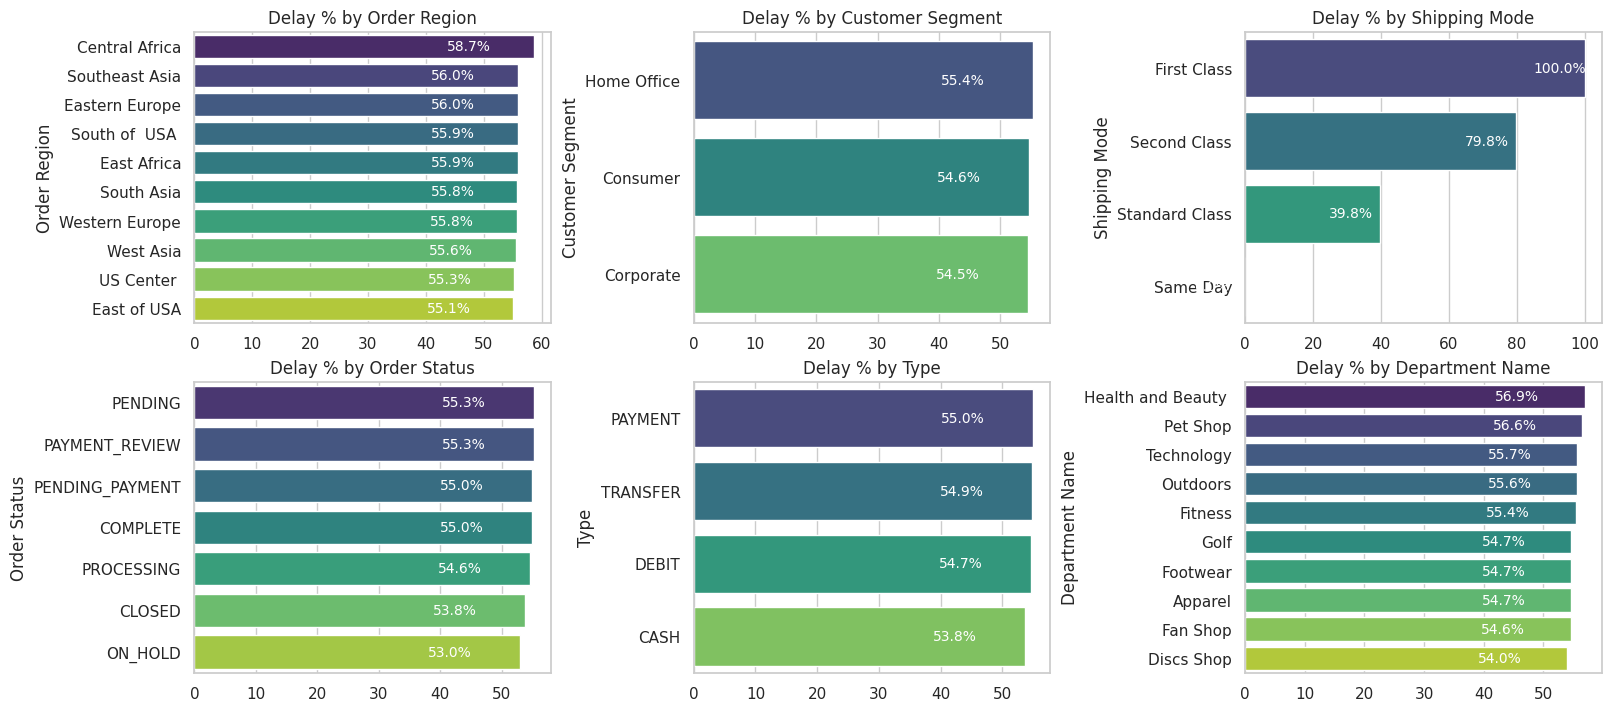

In [ ]:
categories = [
    'Order Region',
    'Customer Segment',
    'Shipping Mode',
    'Order Status',
    'Type',
    'Department Name'
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 7),
    constrained_layout=True
)

axes = axes.flatten()

for ax, category in zip(axes, categories):

    cat_df = compute_delay_pct_by_category(category)

    sns.barplot(
        data=cat_df,
        x='delay_pct',
        y=category,
        ax=ax,
        palette='viridis'
    )

    ax.set_title(f'Delay % by {category}')
    ax.set_xlabel('')
    ax.set_ylabel(category)

    for i, row in cat_df.reset_index().iterrows():
        ax.text(
            row['delay_pct'] - 15,
            i,
            f"{row['delay_pct']:.1f}%",
            va='center',
            fontsize=10,
            color='white'
        )

plt.show()

## 10. Root Cause Analysis

A deeper analysis is performed for Central Africa to identify the operational factors associated with higher late-delivery rates.

The analysis evaluates Shipping Mode, Customer Segment, Department Name, Type, and Order Status and ranks the top driver factors by their delay percentage.

In [ ]:
def top_drivers_for_region(region):

    df_region = df[df['Order Region'] == region].copy()

    drivers = [
        'Shipping Mode',
        'Customer Segment',
        'Department Name',
        'Type',
        'Order Status'
    ]

    all_factors = []

    for factor in drivers:

        temp = (
            df_region.groupby(factor)
            .agg(
                total_orders=('Delay', 'count'),
                late_orders=('Is_Delayed', 'sum'),
                avg_delay=('Delay', 'mean')
            )
            .reset_index()
        )

        temp['delay_pct'] = (
            temp['late_orders'] /
            temp['total_orders'] * 100
        )

        temp['Driver'] = factor

        temp['Factor_Level'] = (
            factor + " : " +
            temp[factor].astype(str)
        )

        all_factors.append(
            temp[
                [
                    'Driver',
                    'Factor_Level',
                    'delay_pct',
                    'avg_delay',
                    'total_orders'
                ]
            ]
        )

    # Combine all driver factors
    final_df = pd.concat(all_factors)

    # Select top 10 drivers
    top_factors = (
        final_df
        .sort_values('delay_pct', ascending=False)
        .head(10)
    )

    # Plot
    plt.figure(figsize=(10, 6))

    bars = plt.barh(
        top_factors['Factor_Level'],
        top_factors['delay_pct'],
        color=primary_color
    )

    plt.xlabel("Delay Percentage (%)")
    plt.ylabel("Driver Factors")
    plt.title(
        f"Top Drivers of Late Delivery in {region}"
    )

    plt.grid(
        True,
        linestyle=':',
        alpha=0.5
    )

    plt.gca().invert_yaxis()

    # Add percentage labels
    for bar in bars:
        width = bar.get_width()

        plt.text(
            width - 10,
            bar.get_y() + bar.get_height() / 2,
            f"{width:.1f}%",
            va='center',
            fontsize=10,
            color='white'
        )

    plt.tight_layout()
    plt.show()

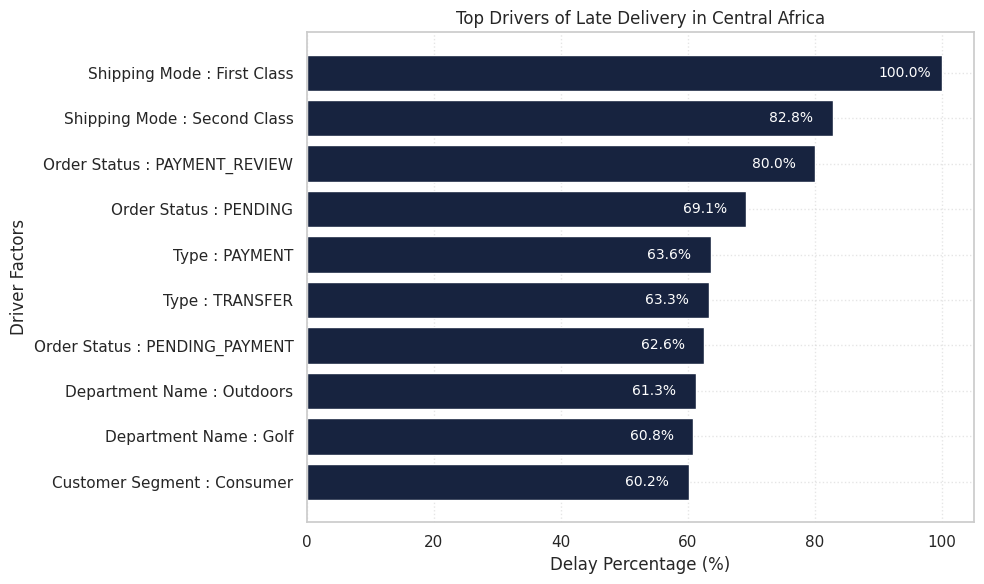

In [ ]:
top_drivers_for_region('Central Africa')

In [ ]:
# Get all available regions
regions = df['Order Region'].dropna().unique()

print("Total Regions:", len(regions))
print("Regions:")
for region in regions:
    print("-", region)

Total Regions: 23
Regions:
- Southeast Asia
- South Asia
- Oceania
- Eastern Asia
- West Asia
- West of USA 
- US Center 
- West Africa
- Central Africa
- North Africa
- Western Europe
- Northern Europe
- Central America
- Caribbean
- South America
- East Africa
- Southern Europe
- Southern Africa
- Central Asia
- Eastern Europe
- East of USA
- South of  USA 
- Canada


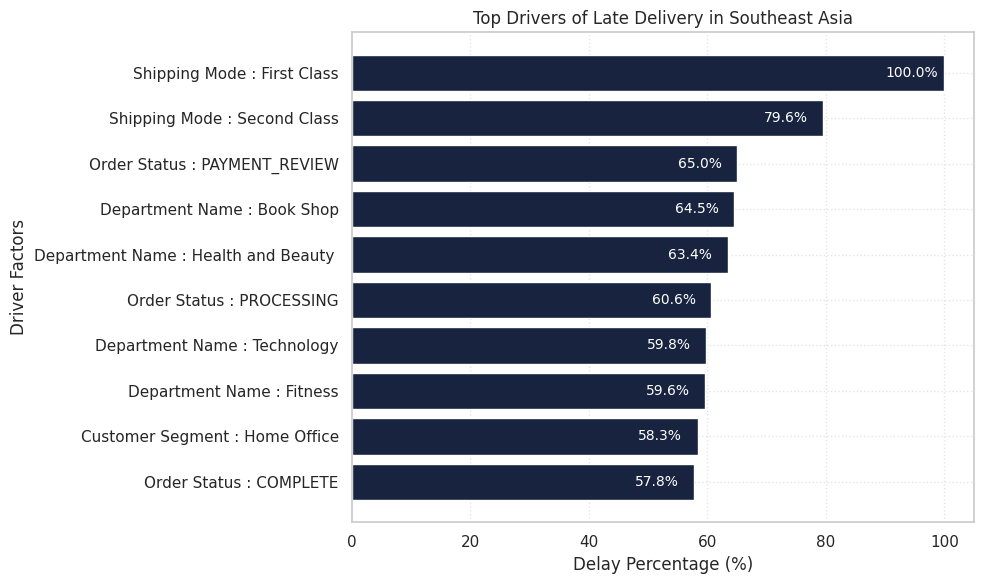

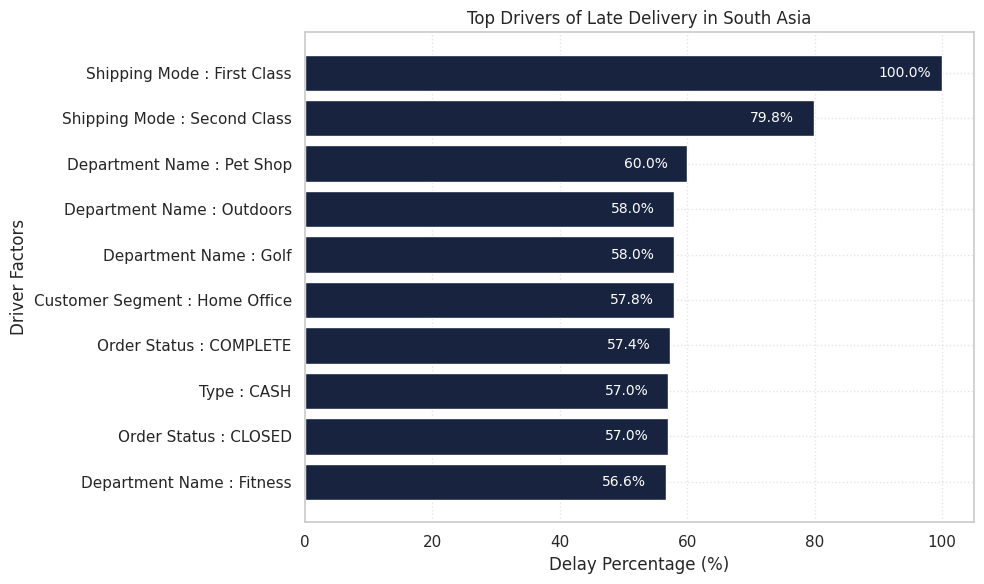

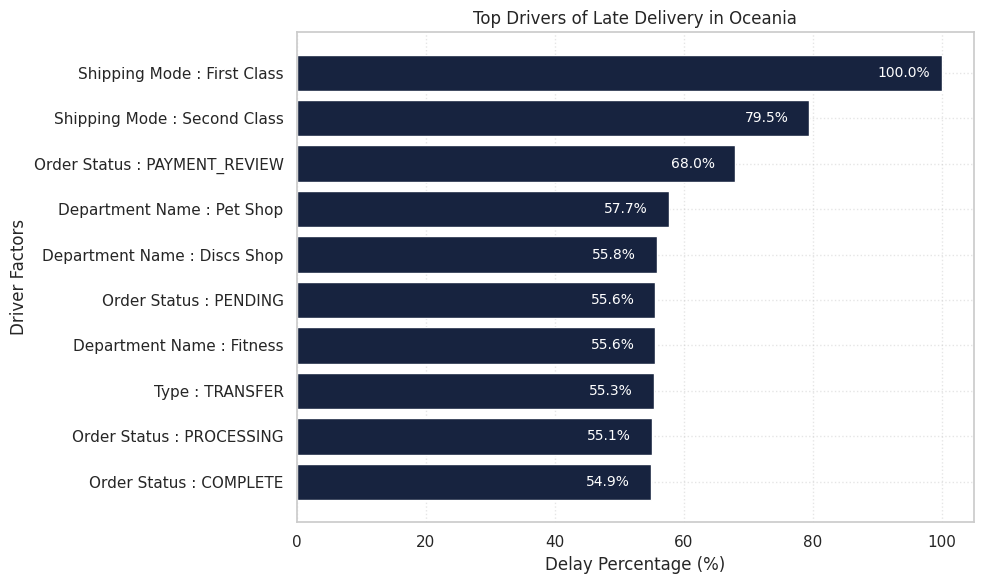

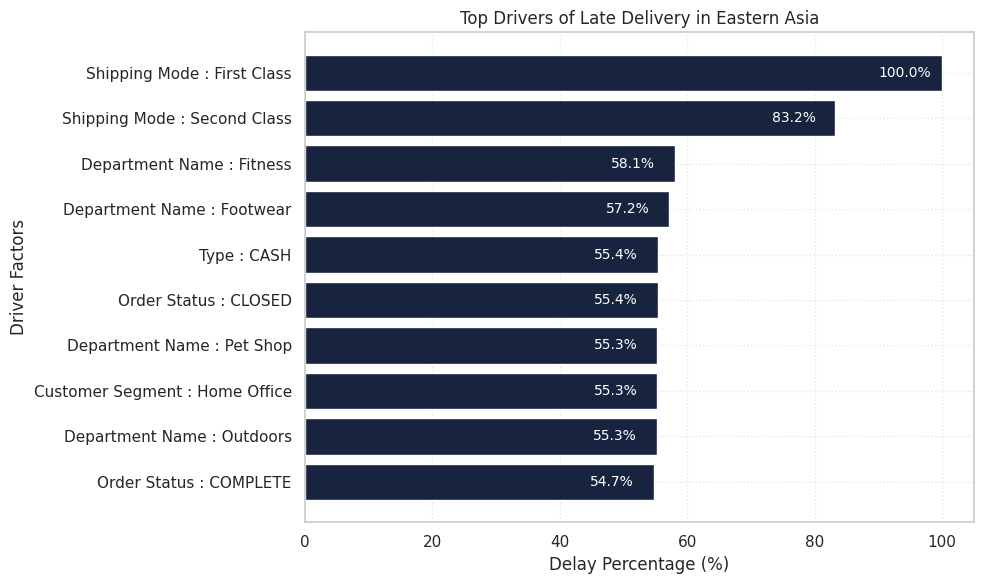

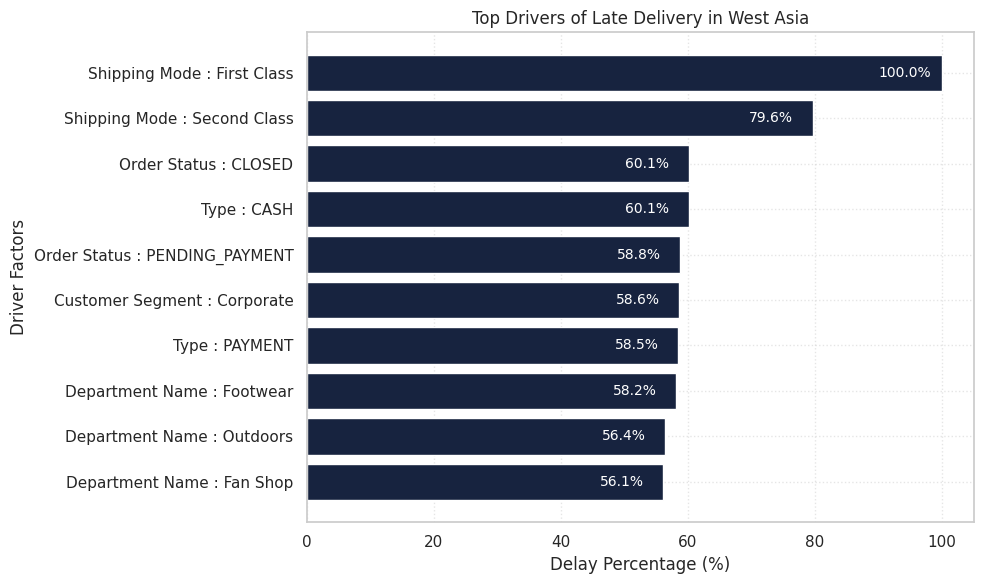

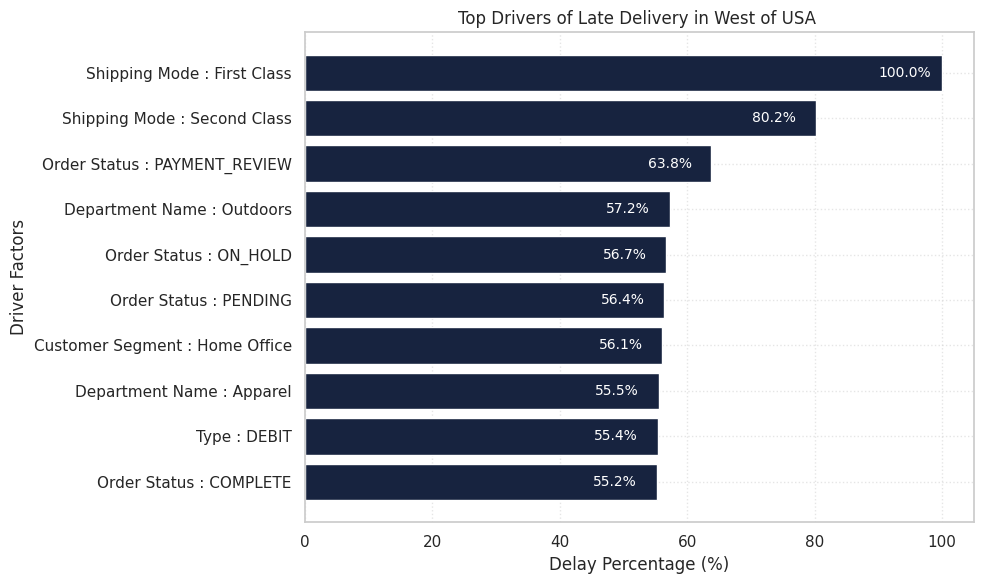

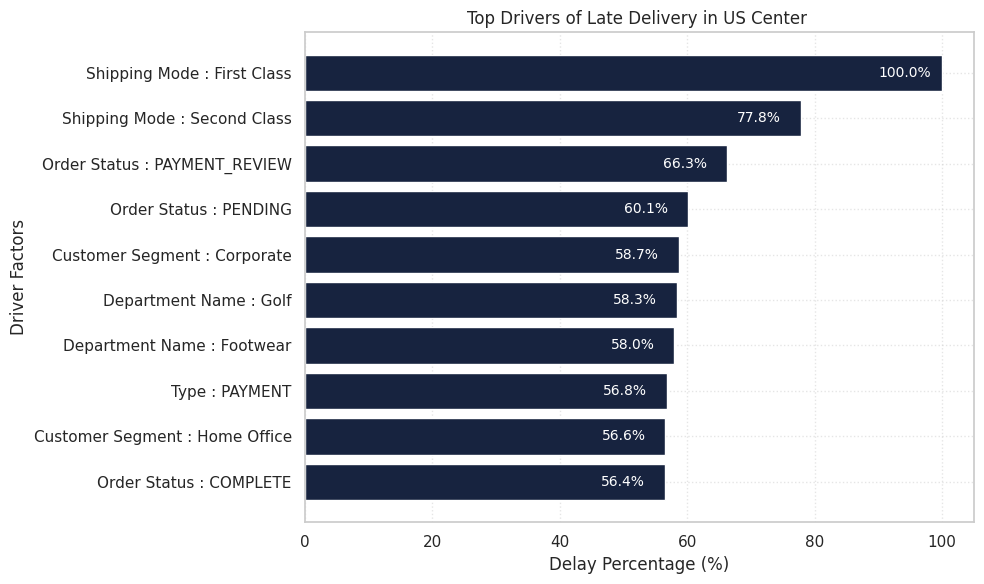

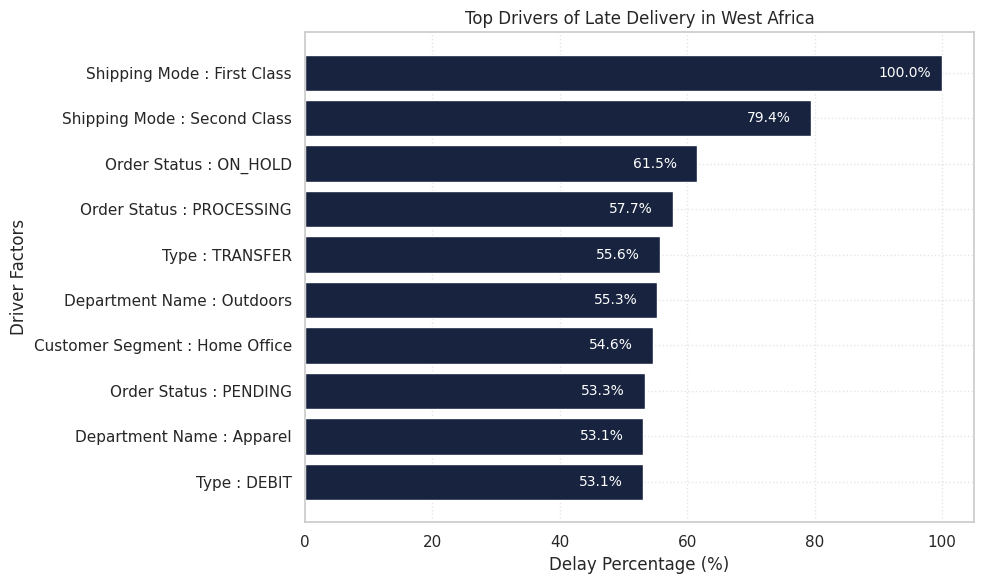

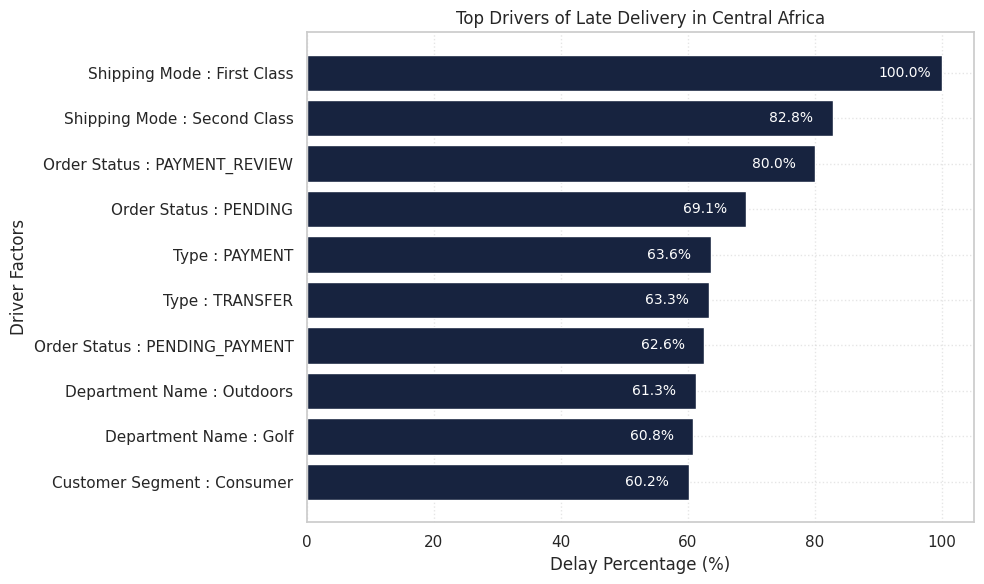

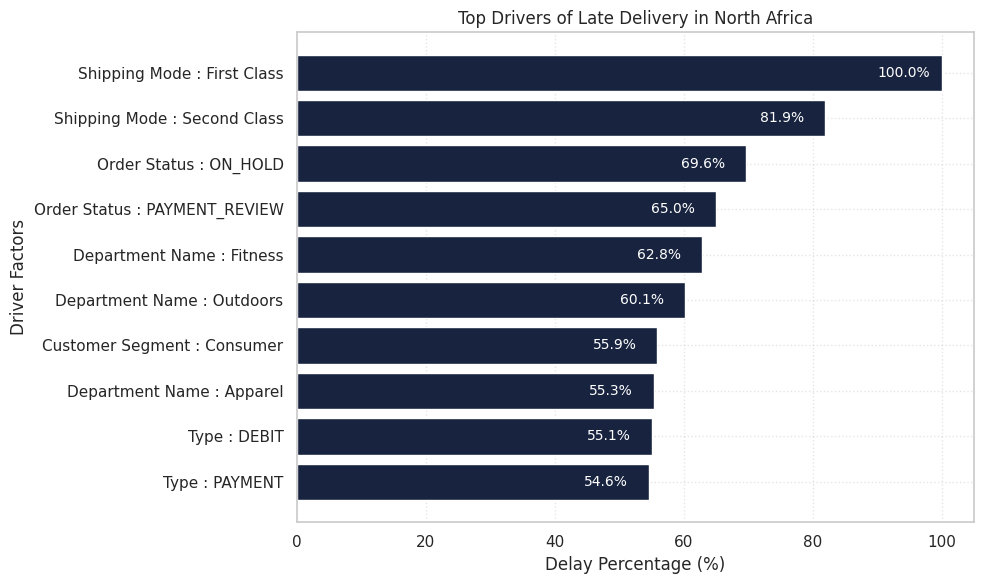

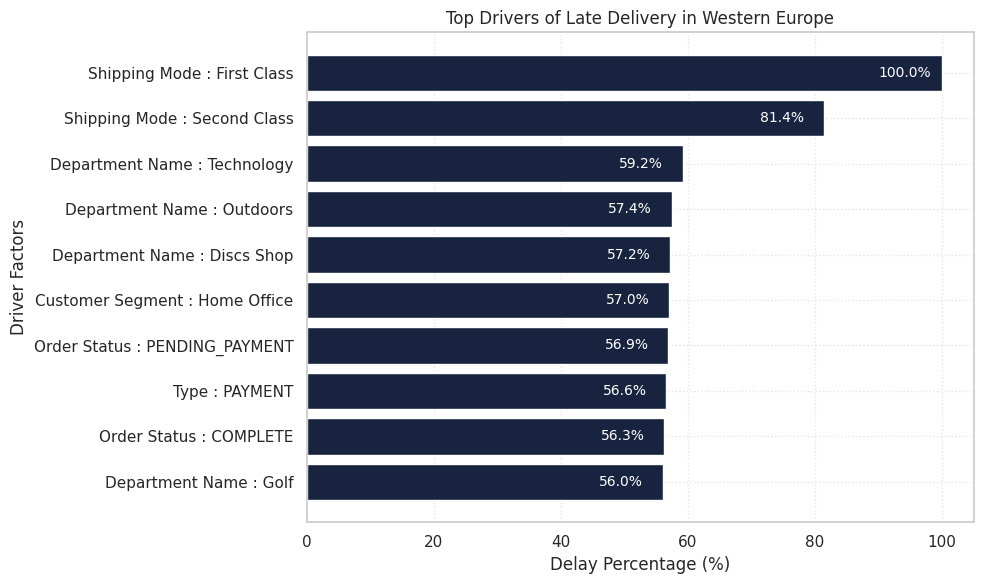

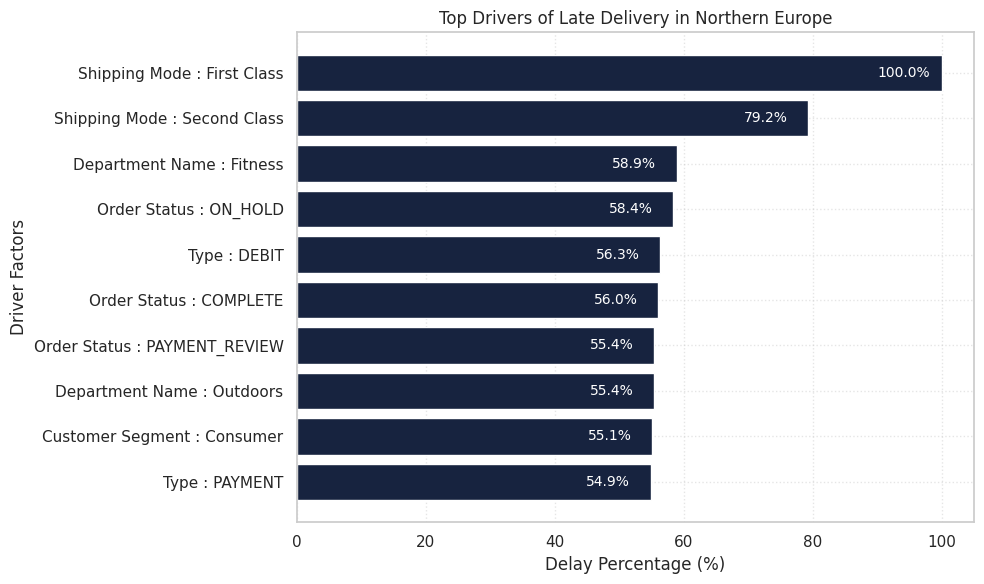

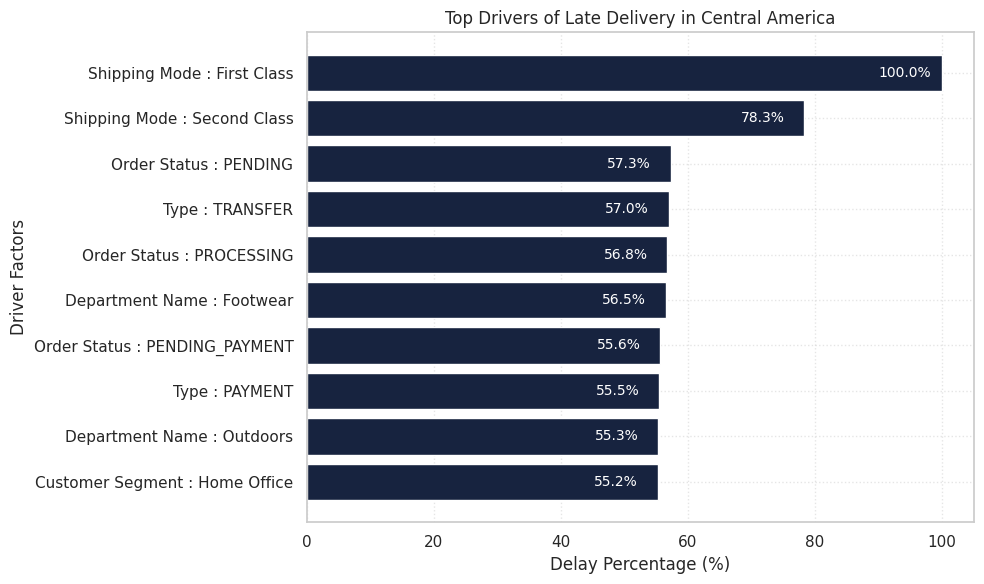

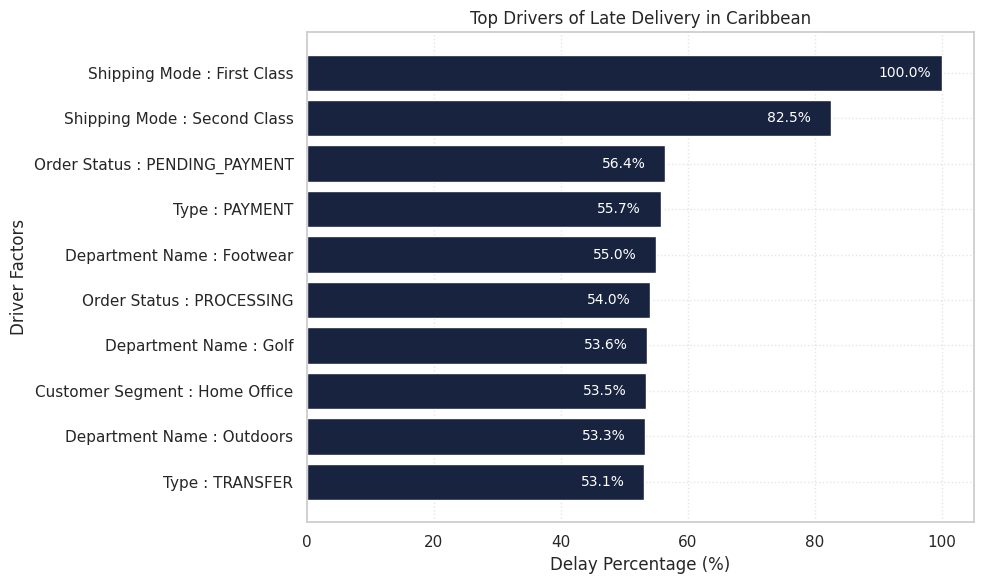

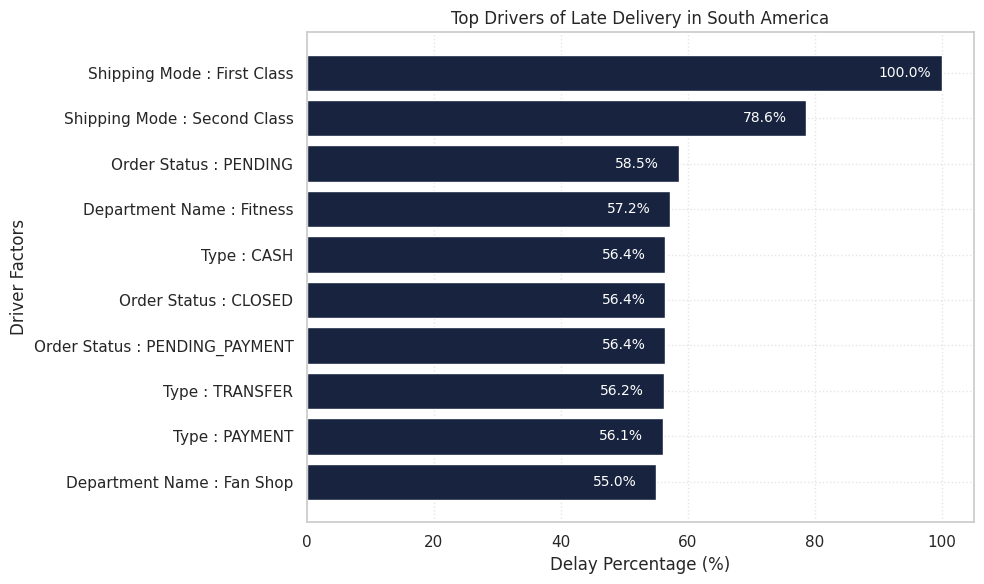

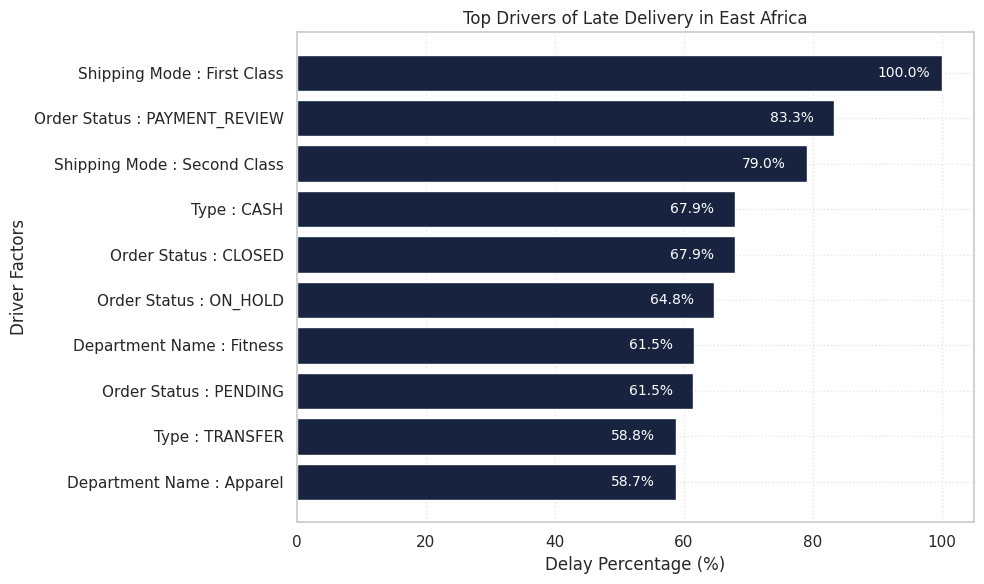

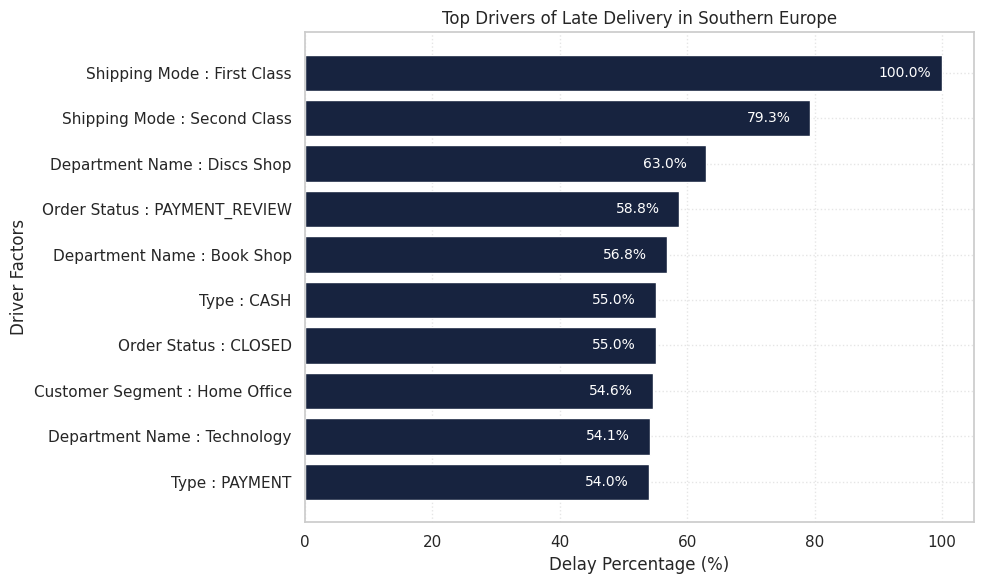

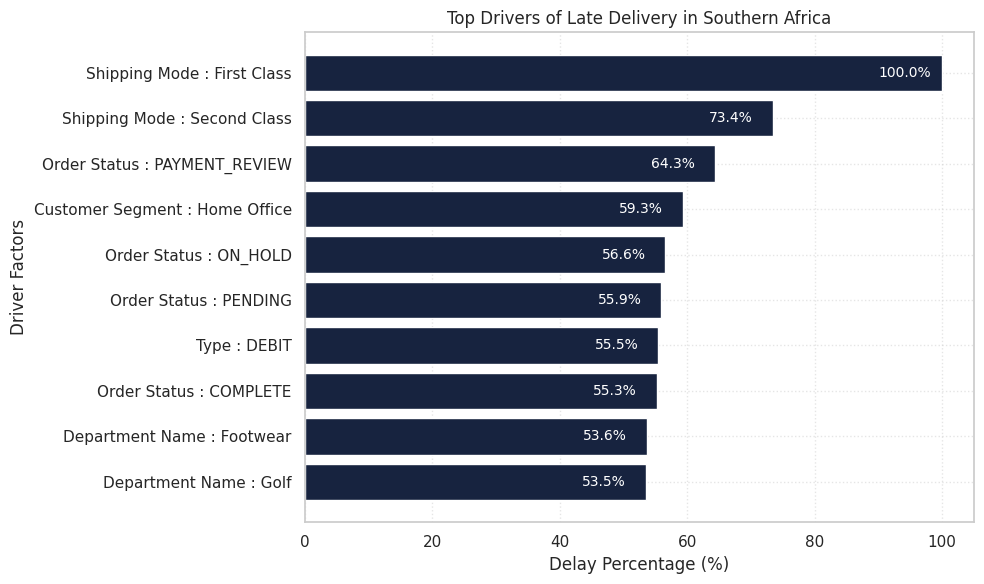

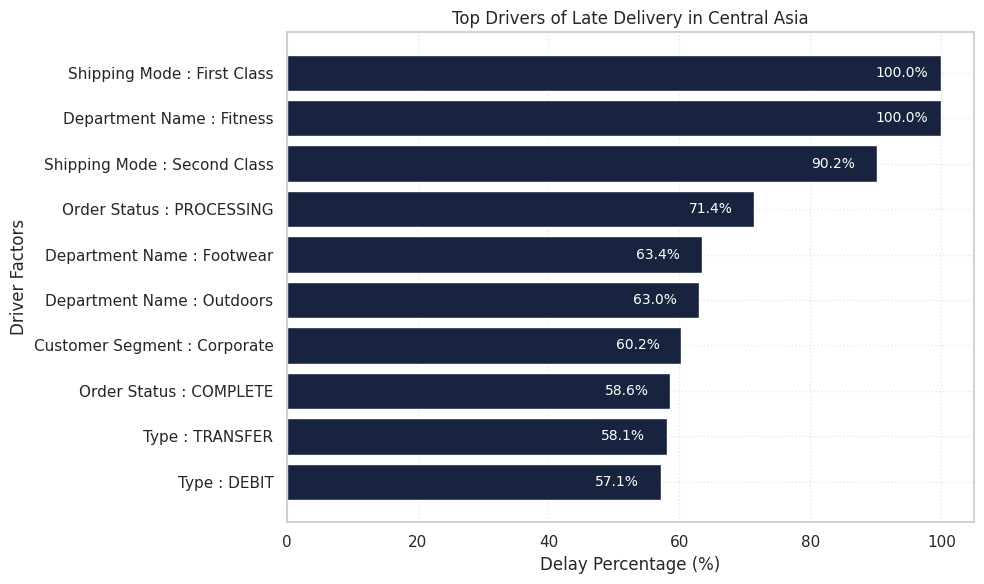

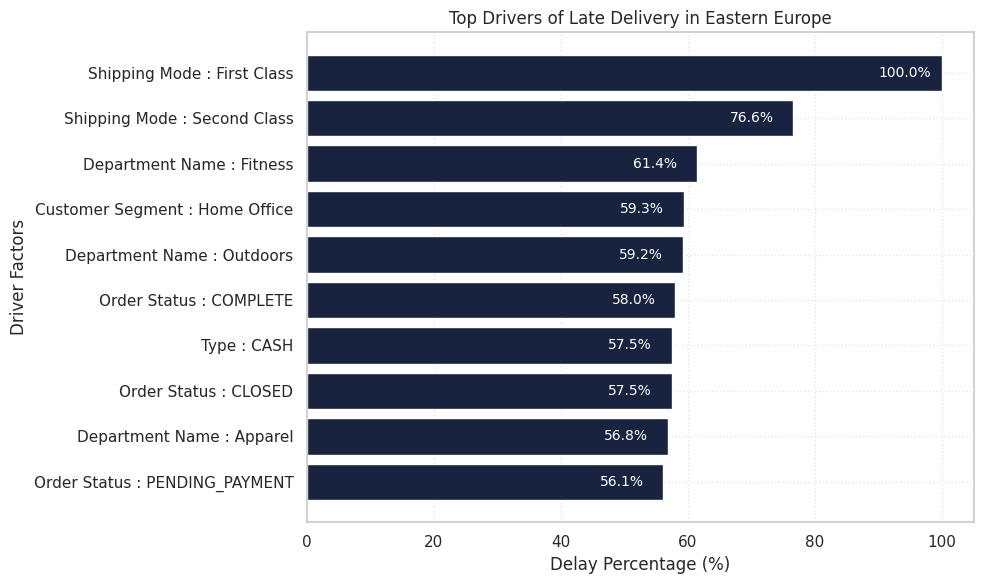

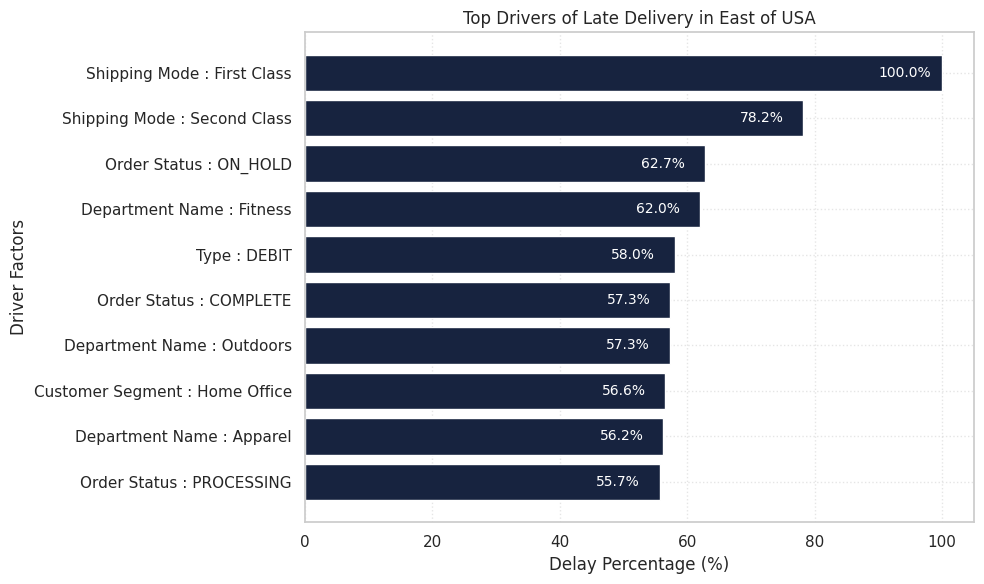

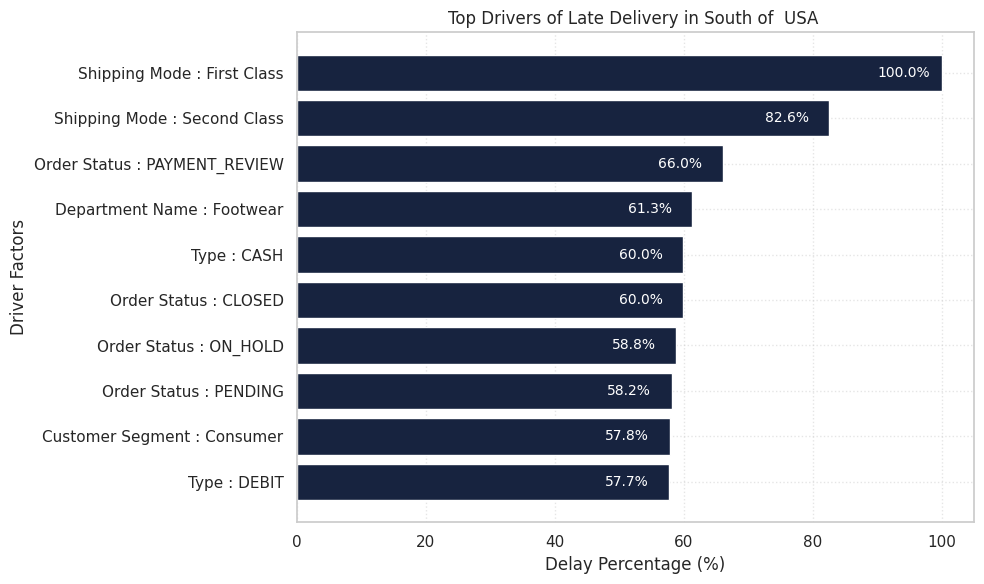

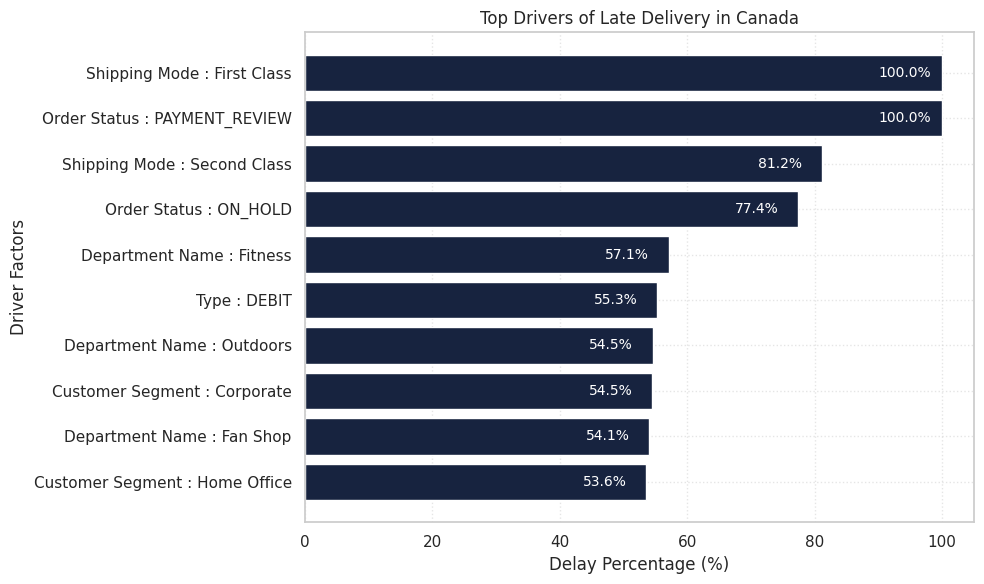

In [ ]:
for region in regions:
    top_drivers_for_region(region)

## 11. Time-Based Delay Patterns

Delay patterns were analyzed across three temporal dimensions: month of year, day of week, and hour of day. This helps identify whether delivery delays show meaningful seasonal, weekly, or intra-day patterns.

In [ ]:
# Delay % by Month, Day of Week, and Hour

delay_by_month = (
    df.groupby('order_month')['Is_Delayed']
      .mean()
      .reset_index()
)

delay_by_month['delay_pct'] = delay_by_month['Is_Delayed'] * 100


delay_by_day = (
    df.groupby('order_day')['Is_Delayed']
      .mean()
      .reset_index()
)

delay_by_day['delay_pct'] = delay_by_day['Is_Delayed'] * 100


delay_by_hour = (
    df.groupby('order_hour')['Is_Delayed']
      .mean()
      .reset_index()
)

delay_by_hour['delay_pct'] = delay_by_hour['Is_Delayed'] * 100

/tmp/ipykernel_1783/4261733266.py:66: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(


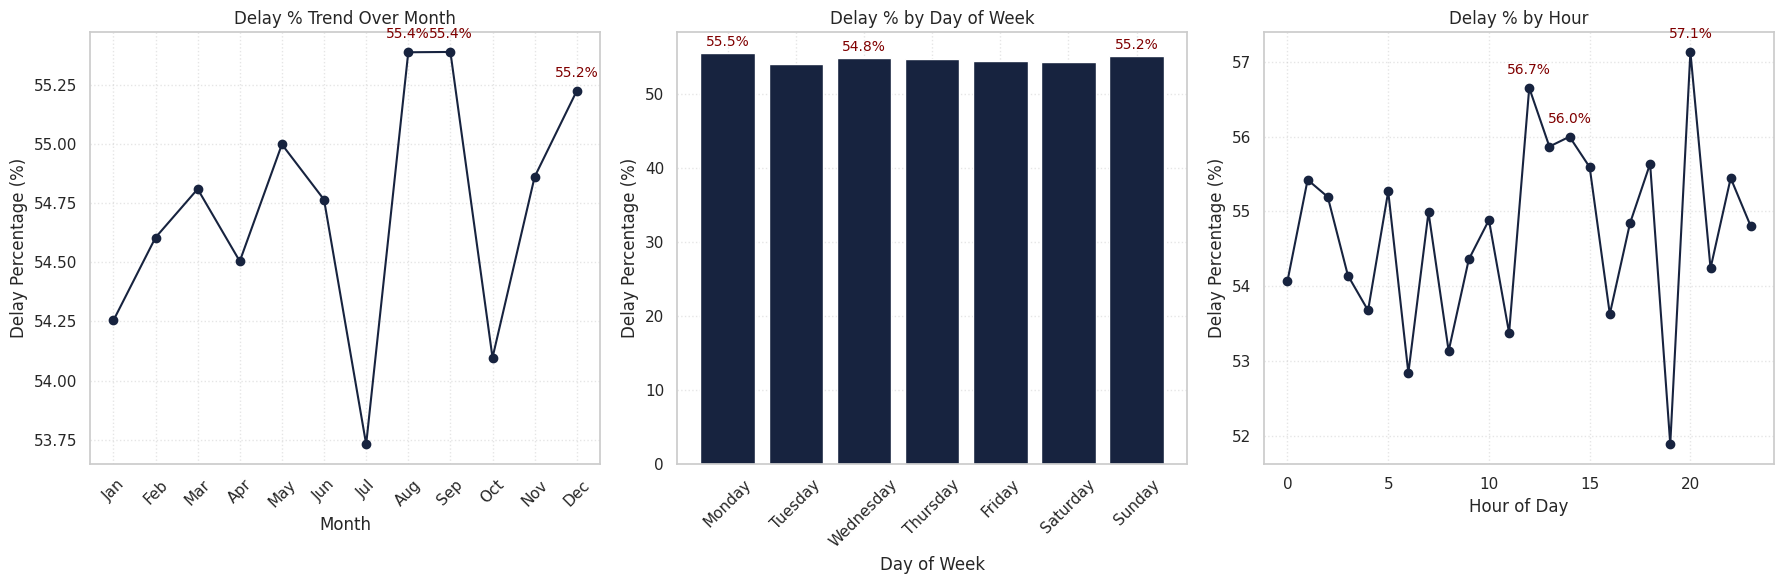

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# -------------------------------
# Delay % Trend Over Month
# -------------------------------
ax1.plot(
    delay_by_month['order_month'],
    delay_by_month['delay_pct'],
    marker='o',
    color=primary_color
)

ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(
    ['Jan','Feb','Mar','Apr','May','Jun',
     'Jul','Aug','Sep','Oct','Nov','Dec'],
    rotation=45
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Delay Percentage (%)")
ax1.set_title("Delay % Trend Over Month")
ax1.grid(True, linestyle=':', alpha=0.5)

top3_month = delay_by_month.nlargest(3, 'delay_pct')

for _, row in top3_month.iterrows():
    ax1.annotate(
        f"{row['delay_pct']:.1f}%",
        (row['order_month'], row['delay_pct']),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center',
        fontsize=10,
        color=danger_color
    )


# -------------------------------
# Delay % by Day of Week
# -------------------------------
day_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

delay_by_day['order_day'] = pd.Categorical(
    delay_by_day['order_day'],
    categories=day_order,
    ordered=True
)

delay_by_day = delay_by_day.sort_values('order_day')

ax2.bar(
    delay_by_day['order_day'],
    delay_by_day['delay_pct'],
    color=primary_color
)

ax2.set_xticklabels(
    delay_by_day['order_day'],
    rotation=45
)

ax2.set_xlabel("Day of Week")
ax2.set_ylabel("Delay Percentage (%)")
ax2.set_title("Delay % by Day of Week")
ax2.grid(True, linestyle=':', alpha=0.5)

top3_day = delay_by_day.nlargest(3, 'delay_pct')

for _, row in top3_day.iterrows():
    height = row['delay_pct']

    ax2.text(
        row['order_day'],
        height + 0.5,
        f'{height:.1f}%',
        ha='center',
        va='bottom',
        fontsize=10,
        color=danger_color
    )


# -------------------------------
# Delay % by Hour
# -------------------------------
ax3.plot(
    delay_by_hour['order_hour'],
    delay_by_hour['delay_pct'],
    marker='o',
    color=primary_color
)

ax3.set_xlabel("Hour of Day")
ax3.set_ylabel("Delay Percentage (%)")
ax3.set_title("Delay % by Hour")
ax3.grid(True, linestyle=':', alpha=0.5)

top3_hour = delay_by_hour.nlargest(3, 'delay_pct')

for _, row in top3_hour.iterrows():
    ax3.annotate(
        f"{row['delay_pct']:.1f}%",
        (row['order_hour'], row['delay_pct']),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center',
        fontsize=10,
        color=danger_color
    )

plt.tight_layout()
plt.show()

## 12. Machine Learning Modeling

A supervised classification model is developed to predict whether an individual order will be delivered late. The target variable is Late_delivery_risk, where 1 represents a late delivery and 0 represents an on-time delivery.

Categorical variables are transformed using frequency encoding, followed by a stratified train-test split. SMOTE is then applied to the training data to address class imbalance before training a Random Forest Classifier.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report
)
from sklearn.ensemble import RandomForestClassifier
from collections import Counter
from imblearn.over_sampling import SMOTE

In [ ]:
X = df[
    [
        'Type',
        'Days for shipment (scheduled)',
        'Category Name',
        'Customer Segment',
        'Department Name',
        'Order Region',
        'Shipping Mode',
        'order_month',
        'order_hour'
    ]
]

y = df['Late_delivery_risk']

### Feature Encoding and Data Splitting

Categorical variables are converted into numerical values using frequency encoding. This approach replaces each category with its frequency in the dataset while keeping the feature representation compact.

After encoding the categorical variables, the original text-based categorical columns are removed. The resulting numerical dataset is then divided into training and testing sets using an 80:20 split with stratification to preserve the target class distribution.

In [ ]:
# Create an independent copy of the selected features
X = df[
    [
        'Type',
        'Days for shipment (scheduled)',
        'Category Name',
        'Customer Segment',
        'Department Name',
        'Order Region',
        'Shipping Mode',
        'order_month',
        'order_hour'
    ]
].copy()

# Identify categorical columns
cat_cols = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Categorical columns:", cat_cols)

# Frequency encoding
for col in cat_cols:
    freq = X[col].value_counts(normalize=True)
    X.loc[:, f'{col}_freq'] = X[col].map(freq)

# Drop original categorical columns
X_encoded = X.drop(columns=cat_cols)

print("Shape after freq encoding:", X_encoded.shape)

# Use encoded features for modeling
X = X_encoded

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Categorical columns: ['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Order Region', 'Shipping Mode']
Shape after freq encoding: (172765, 9)


### Train-Test Split

The encoded dataset is divided into training and testing sets using an 80:20 split. Stratified sampling is used to maintain the same proportion of late and on-time delivery classes in both datasets.

The training data is used to build the machine learning model, while the test data is kept separate for evaluating the model's performance on unseen orders.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (138212, 9)
Testing set shape: (34553, 9)


### Target Class Distribution

Before applying any balancing technique, the distribution of the target variable is examined to identify class imbalance between on-time and late deliveries.

In [ ]:
y.value_counts()

,count
Late_delivery_risk,
1,98977
0,73788


### Class Imbalance Handling using SMOTE

The target variable contains an imbalance between late and on-time delivery orders. SMOTE (Synthetic Minority Over-sampling Technique) is applied only to the training data to balance the two classes.

The test data remains unchanged so that model evaluation reflects performance on the original distribution of unseen orders.

In [ ]:
# Balancing the training data using SMOTE

print("Before balancing (train):", Counter(y_train))

smote = SMOTE(random_state=42)

X_train_bal, y_train_bal = smote.fit_resample(
    X_train,
    y_train
)

print("After balancing (train):", Counter(y_train_bal))

Before balancing (train): Counter({1: 79182, 0: 59030})
After balancing (train): Counter({0: 79182, 1: 79182})


### Random Forest Classifier

A Random Forest Classifier is trained on the SMOTE-balanced training dataset. The model learns patterns associated with late and on-time deliveries and is then evaluated on the untouched test dataset.

In [ ]:
rf_model_balanced = RandomForestClassifier(
    random_state=42
)

rf_model_balanced.fit(
    X_train_bal,
    y_train_bal
)

y_pred_rf_balanced = rf_model_balanced.predict(X_test)

### Model Evaluation

The trained Random Forest model is evaluated using accuracy, precision, recall, and a detailed classification report. These metrics help assess how effectively the model identifies late-delivery orders.

In [ ]:
def evaluate_model(y_true, y_pred, model_name):
    print(f"\n--- {model_name} ---")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 2))
    print("Precision:", round(precision_score(y_true, y_pred), 2))
    print("Recall:", round(recall_score(y_true, y_pred), 2))
    print(
        "\nClassification Report:\n",
        classification_report(y_true, y_pred)
    )

In [ ]:
evaluate_model(
    y_test,
    y_pred_rf_balanced,
    "Random Forest Classifier"
)


--- Random Forest Classifier ---
Accuracy: 0.74
Precision: 0.79
Recall: 0.75

Classification Report:
               precision    recall  f1-score   support

           0       0.68      0.73      0.70     14758
           1       0.79      0.75      0.77     19795

    accuracy                           0.74     34553
   macro avg       0.73      0.74      0.73     34553
weighted avg       0.74      0.74      0.74     34553



### Random Forest Model Performance Summary

The Random Forest Classifier was trained using SMOTE-balanced training data and evaluated on 34,553 unseen test records. The model achieved 74% overall accuracy, with 79% precision and 75% recall for identifying late-delivery orders.

The classification report shows an F1-score of 0.77 for late-delivery orders (Class 1), indicating that the model provides a useful predictive signal for identifying orders at risk of late delivery.